<a href="https://colab.research.google.com/github/SaraLarkem/ireland-fuel-grocery-viz/blob/main/notebooks/02_Trend_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook 02: Trend Analysis - Fuel and Grocery CPI

**Goal:** Identify overarching long-term trends, seasonal cycles, and Year-over-Year (YoY) inflation rates in the cleaned fuel and grocery dataset.

This notebook establishes the baseline mathematical trajectories of inflation and energy costs. By separating the raw data into distinct trend and seasonal components, we provide the foundational context required before investigating specific supply shocks (Notebook 04) or complex elasticity models (Notebook 06).

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.seasonal import seasonal_decompose

# Set style for consistency with final visualizations
plt.style.use('seaborn-v0_8-whitegrid')
colors = {'Petrol': '#1f77b4', 'Diesel': '#ff7f0e', 'CPI': '#2ca02c'}

# 1. Load the dataset directly from GitHub to avoid folder path errors
url = 'https://raw.githubusercontent.com/SaraLarkem/ireland-fuel-grocery-viz/refs/heads/main/data/cleaned_fuel_grocery_data.csv'
df = pd.read_csv(url)

# 2. Rename columns for easier access in code
df = df.rename(columns={
    'Food and non-alcoholic beverages': 'Grocery_CPI'
})

# 3. Set the datetime index using the existing 'Month_DT' column
df['Month_DT'] = pd.to_datetime(df['Month_DT'])
df.set_index('Month_DT', inplace=True)
df.sort_index(inplace=True)

# 4. Basic validation check
print(f"Dataset range: {df.index.min().date()} to {df.index.max().date()}")
print("\n--- Cleaned Data Head ---")
print(df[['Diesel', 'Petrol', 'Grocery_CPI']].head())

Dataset range: 2016-01-01 to 2026-09-01

--- Cleaned Data Head ---
            Diesel  Petrol  Grocery_CPI
Month_DT                               
2016-01-01    65.0    72.8         90.7
2016-02-01    61.1    70.5         90.0
2016-03-01    61.9    70.0         90.3
2016-04-01    64.2    73.1         90.0
2016-05-01    65.3    74.7         90.0


### 1. Smoothing Volatility and Calculating YoY Growth
Raw monthly data contains short-term noise. We apply 3-month (quarterly) and 12-month (annual) rolling averages to extract the true underlying direction. We also calculate the 12-month percentage change (YoY Inflation), which is the standard metric used to communicate inflation to consumers.

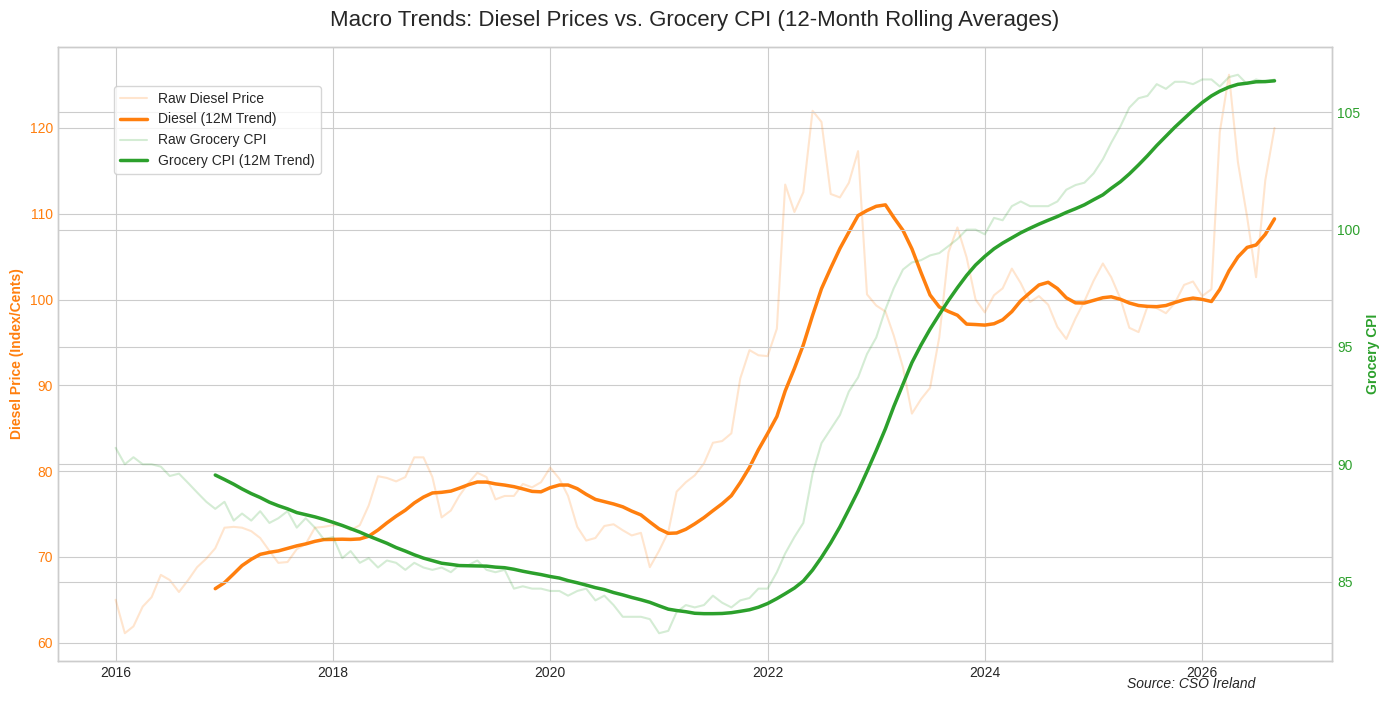

In [ ]:
# Calculate rolling averages for Diesel and CPI
df['Diesel_3M_Avg'] = df['Diesel'].rolling(window=3).mean()
df['Diesel_12M_Avg'] = df['Diesel'].rolling(window=12).mean()

df['CPI_3M_Avg'] = df['Grocery_CPI'].rolling(window=3).mean()
df['CPI_12M_Avg'] = df['Grocery_CPI'].rolling(window=12).mean()

# Calculate Year-over-Year (YoY) percentage change (12-month shift)
df['Diesel_YoY_Pct'] = df['Diesel'].pct_change(periods=12) * 100
df['CPI_YoY_Pct'] = df['Grocery_CPI'].pct_change(periods=12) * 100

# Plotting the smoothed macro trends
fig, ax1 = plt.subplots(figsize=(14, 7))

# Plot Diesel Trend (Primary Y-Axis)
ax1.plot(df.index, df['Diesel'], color=colors['Diesel'], alpha=0.2, label='Raw Diesel Price')
ax1.plot(df.index, df['Diesel_12M_Avg'], color=colors['Diesel'], linewidth=2.5, label='Diesel (12M Trend)')
ax1.set_ylabel('Diesel Price (Index/Cents)', color=colors['Diesel'], fontweight='bold')
ax1.tick_params(axis='y', labelcolor=colors['Diesel'])

# Plot CPI Trend (Secondary Y-Axis)
ax2 = ax1.twinx()
ax2.plot(df.index, df['Grocery_CPI'], color=colors['CPI'], alpha=0.2, label='Raw Grocery CPI')
ax2.plot(df.index, df['CPI_12M_Avg'], color=colors['CPI'], linewidth=2.5, label='Grocery CPI (12M Trend)')
ax2.set_ylabel('Grocery CPI', color=colors['CPI'], fontweight='bold')
ax2.tick_params(axis='y', labelcolor=colors['CPI'])

plt.title('Macro Trends: Diesel Prices vs. Grocery CPI (12-Month Rolling Averages)', fontsize=16, pad=15)
fig.legend(loc='upper left', bbox_to_anchor=(0.08, 0.88), frameon=True)
plt.figtext(0.9, 0.01, 'Source: CSO Ireland', ha='right', fontsize=10, style='italic')

plt.tight_layout()
plt.show()

### 2. Time-Series Decomposition
To ensure our elasticity models in Notebook 06 are accurate, we must isolate routine seasonal cycles (e.g., standard holiday price increases) from the overarching trend and the unpredictable "residuals" (the economic shocks).

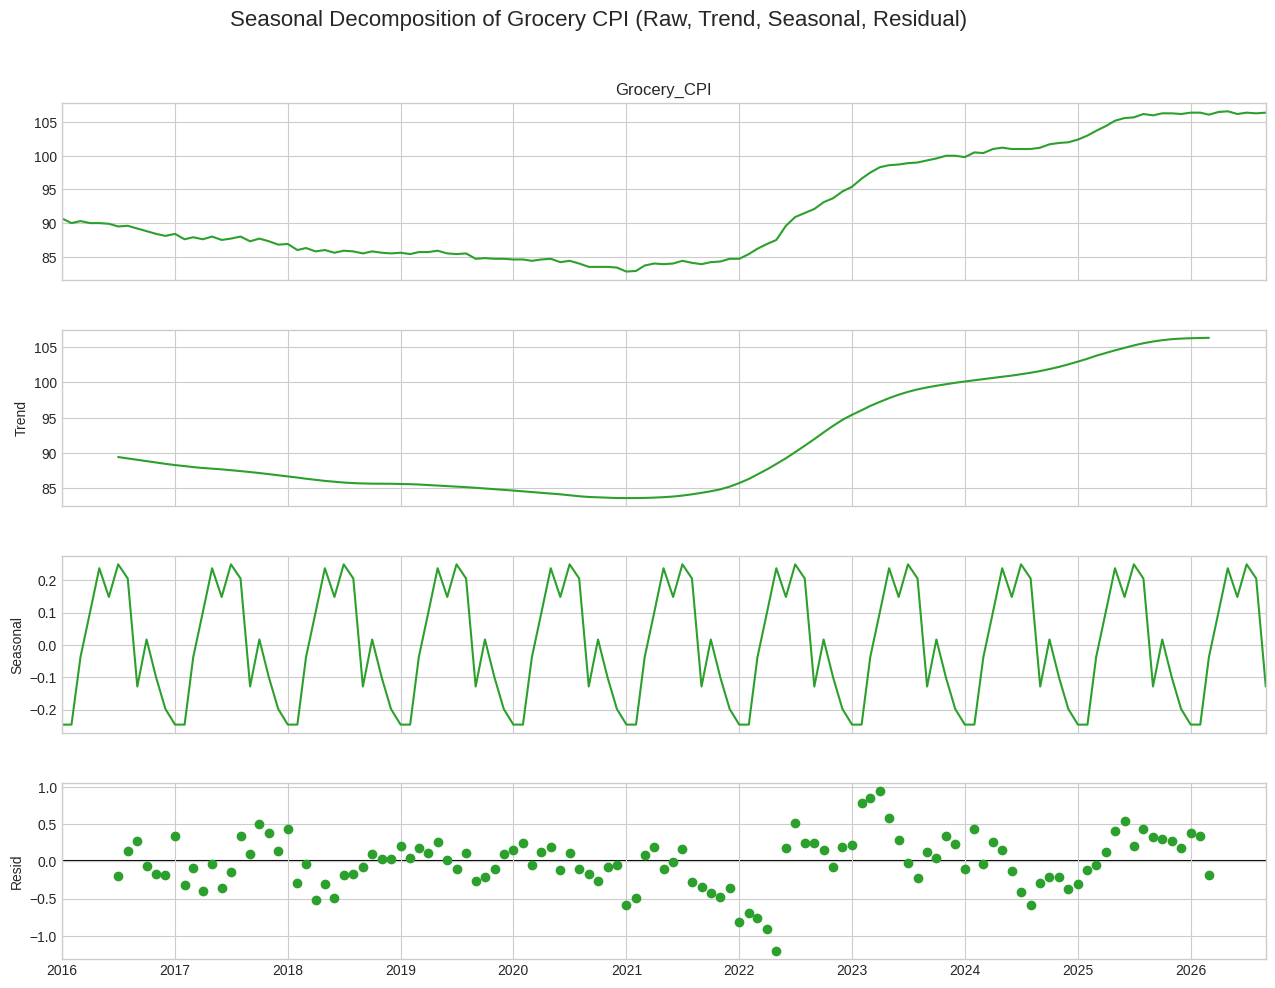

In [ ]:
# Isolate the CPI time series and drop any NaNs
cpi_ts = df['Grocery_CPI'].dropna()

# Perform additive decomposition (period=12 for monthly data)
decomposition = seasonal_decompose(cpi_ts, model='additive', period=12)

# Extract components back into the main dataframe
df.loc[cpi_ts.index, 'CPI_Trend'] = decomposition.trend
df.loc[cpi_ts.index, 'CPI_Seasonal'] = decomposition.seasonal
df.loc[cpi_ts.index, 'CPI_Residual'] = decomposition.resid

# Plot the decomposition
fig = decomposition.plot()
fig.set_size_inches(14, 10)
fig.suptitle('Seasonal Decomposition of Grocery CPI (Raw, Trend, Seasonal, Residual)', fontsize=16, y=1.02)

# Customize subplot colors to match the project design system
axes = fig.get_axes()
for ax in axes:
    ax.lines[0].set_color(colors['CPI'])

plt.show()

### 3. Handoff to Shocks and Modeling Notebooks
With the rolling averages, YoY percentage changes, and seasonal residuals calculated, we export this enriched dataset.
* **Notebook 06** uses the `_YoY_Pct` and `_Residual` columns to model how external shocks deviate from these baseline trends.

In [ ]:
import os

# Ensure the data directory exists
os.makedirs('data', exist_ok=True)

# Save the enriched dataset for the next stages in the pipeline
export_path = 'data/02_trend_analysis_output.csv'

# Drop the original string Month columns to keep the export clean, as we now use Month_DT
df_export = df.drop(columns=['Month', 'Month_Diff'], errors='ignore')
df_export.to_csv(export_path)

print(f"Trend analysis complete. Enriched dataset exported to: {export_path}")

Trend analysis complete. Enriched dataset exported to: data/02_trend_analysis_output.csv
